In [11]:
from pathlib import Path
import os, sys

# Auto-set repo root (expects Data/ and predictions/ at root)
cwd = Path.cwd()
REPO_ROOT = None
for parent in [cwd, *cwd.parents]:
    if (parent / "Data").exists() and (parent / "predictions").exists():
        REPO_ROOT = parent
        break
if REPO_ROOT is None:
    REPO_ROOT = cwd
os.chdir(REPO_ROOT)

# Add notebook-local modules to import path
src_candidates = [
    REPO_ROOT / "notebooks",
    REPO_ROOT / "code_repository" / "notebooks",
]
for SRC in src_candidates:
    if SRC.exists() and str(SRC) not in sys.path:
        sys.path.insert(0, str(SRC))
        break
print(f"Working dir: {Path.cwd()}")


Working dir: /mnt/nas/PhD/Code/Ms_paint/code_repository


In [12]:
from analysis.plot_style import apply_style, save_figure, set_save_dir
FIGURE_ID = "figure4"
FIG_DIR = set_save_dir(REPO_ROOT, FIGURE_ID)
apply_style()


In [13]:
from analysis.figure4_best_helpers import (
    _collect_balanced_long as _collect_balanced_long_impl,
    _posthoc_conover_friedman_vs_best as _posthoc_conover_friedman_vs_best_impl,
)


In [14]:
# =========================
# 0) SETUP & CONFIG
# =========================
import os
from pathlib import Path

# --- set your experiment ---
os.chdir(REPO_ROOT)
EXP        = "Feature_augmentation_experiment"
TASK       = "binary"

# Where your previous pipeline saved per-cycle CSVs:
BASE_OUTDIR = Path(f"analysis_exports/Feature_augmentation_experiment")
assert BASE_OUTDIR.exists(), f"Not found: {BASE_OUTDIR}"

# Automatically detect which models have per-cycle tables
MODEL_TYPES = sorted([p.name for p in BASE_OUTDIR.iterdir() if p.is_dir() and (p / f"{p.name}_per_cycle_all_metrics.csv").exists()])
print("Models detected:", MODEL_TYPES)

# Feature sets to compare (as decided from your PR_AUC/ROC_AUC rank-sum analysis)
TOP_FEATURES = [
    "CellPaint+ECFP+Proteomics",
    "CellPaint+ECFP+MIC+Proteomics",
    "CellPaint+ECFP+GC+MIC+Proteomics",
]

# Metrics to compare across models
METRICS_CMP = ["roc_auc", "pr_auc", "mcc"]

# Output folder for this notebook
CMP_OUTDIR = BASE_OUTDIR / "cross_model_on_topsets"
CMP_OUTDIR.mkdir(parents=True, exist_ok=True)
CMP_OUTDIR


Models detected: ['lightgbm', 'mlp', 'pytorch_mlp', 'rf', 'tabm', 'xgboost']


PosixPath('analysis_exports/Feature_augmentation_experiment/cross_model_on_topsets')

In [15]:
# ===== Globals (restored) =====
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np, pandas as pd
import pingouin as pg
from statsmodels.stats.multitest import multipletests
from matplotlib.patches import Patch

# Base output from your previous pipeline must exist
assert 'BASE_OUTDIR' in globals(), "Define BASE_OUTDIR before running."
MODEL_ORDER = ["rf", "lightgbm", "xgboost", "mlp", "pytorch_mlp", "tabm"]  # low→high complexity (x-axis groups)
FEATURES = [
    "CellPaint+ECFP+Proteomics",
    "CellPaint+ECFP+MIC+Proteomics",
    "CellPaint+ECFP+GC+MIC+Proteomics",
]
FEATURE_SHORT = {
    "CellPaint+ECFP+Proteomics": "CP+ECFP+Prot",
    "CellPaint+ECFP+MIC+Proteomics": "CP+ECFP+MIC+Prot",
    "CellPaint+ECFP+GC+MIC+Proteomics": "CP+ECFP+GC+MIC+Prot",
}
METRICS = ["roc_auc", "pr_auc", "mcc"]
ALPHA = 0.05
OUTDIR = BASE_OUTDIR / "global_grouped_signif"
OUTDIR.mkdir(parents=True, exist_ok=True)

# Colors + hatches
C_RED  = "#c45c5c"
C_BLUE = "#1f77b4"
C_GREY = "#9e9e9e"
HATCH_MAP = {
    "CellPaint+ECFP+Proteomics": "",
    "CellPaint+ECFP+MIC+Proteomics": "ooo",  # small circles, denser by repetition
    "CellPaint+ECFP+GC+MIC+Proteomics": "xx",
}

# Box style defaults (black outlines, black median)
mpl.rcParams["boxplot.medianprops.color"]   = "black"
mpl.rcParams["boxplot.boxprops.color"]      = "black"
mpl.rcParams["boxplot.whiskerprops.color"]  = "black"
mpl.rcParams["boxplot.capprops.color"]      = "black"

def _fmt_p(p): 
    return f"{p:.3g}" if p >= 1e-3 else f"{p:.1e}"

# ===== Plot function with legends below =====
def plot_grouped_with_significance_globalbest(metric: str, show_points="outliers", whis=1.5):
    """
    Global grouped plot across models×features with significance coloring vs global best.
    Feature identity is shown via hatch patterns; color encodes significance.
    Legends are placed beneath the plot.
    """
    long = _collect_balanced_long(metric)
    if long.empty:
        print(f"[{metric}] No globally balanced data found.")
        return

    def _lab(m, f): return f"{m} | {FEATURE_SHORT[f]}"
    long = long.copy()
    long["cond"] = long.apply(lambda r: _lab(r["model_type"], r["feature_set"]), axis=1)

    wide = long.pivot_table(index="cv_cycle", columns="cond", values="value", aggfunc="mean").dropna(axis=0, how="any")
    best_label, means, Q = _posthoc_conover_friedman_vs_best(wide, alpha=ALPHA)

    present_models = [m for m in MODEL_ORDER if m in long["model_type"].unique().tolist()]
    group_gap = 1.2
    offsets = [-0.6, 0.0, 0.6]  # FEATURES order
    box_width = 0.6

    best_mean = float(means.loc[best_label])
    color_map = {}
    for cond in wide.columns:
        if cond == best_label:
            color_map[cond] = C_BLUE
        else:
            q = Q.loc[best_label, cond] if (best_label in Q.index and cond in Q.columns) else np.nan
            color_map[cond] = C_RED if (not np.isnan(q)) and (q < ALPHA) and (means.loc[cond] < best_mean) else C_GREY

    xpos_map, xpos = {}, 0.0
    for m in present_models:
        xpos_map[m] = xpos
        xpos += (offsets[-1] - offsets[0]) + group_gap

    fried = pg.friedman(
        data=long.rename(columns={"value":"value"})[["cv_cycle","cond","value"]],
        dv="value", within="cond", subject="cv_cycle"
    )
    fried_p = float(fried.filter(like="p").iloc[0,0])

    fig, ax = plt.subplots(figsize=(14, 6.6))

    # draw each box with: facecolor = significance color, hatch = feature identity, dots = black
    for m in present_models:
        for f, dx in zip(FEATURES, offsets):
            cond = _lab(m, f)
            if cond not in wide.columns:
                continue
            vals = wide[cond].dropna().values
            cx = xpos_map[m] + dx
            bp = ax.boxplot([vals], positions=[cx], widths=box_width,
                            patch_artist=True, showfliers=False,
                            medianprops=dict(linewidth=1.4, color="black"),
                            boxprops=dict(linewidth=1, color="black"),
                            whiskerprops=dict(linewidth=1, color="black"),
                            capprops=dict(linewidth=1, color="black"))
            for patch in bp["boxes"]:
                patch.set_facecolor(color_map.get(cond, C_GREY))
                patch.set_edgecolor("black")
                patch.set_linewidth(1)
                patch.set_hatch(HATCH_MAP[f])

            # dots always black
            if show_points != "none":
                if show_points == "all":
                    pts = vals
                else:  # "outliers"
                    q1, q3 = np.percentile(vals, [25, 75])
                    iqr = q3 - q1; lo = q1 - whis*iqr; hi = q3 + whis*iqr
                    pts = vals[(vals < lo) | (vals > hi)]
                if len(pts):
                    xx = cx + (np.random.rand(len(pts)) - 0.5) * 0.22
                    ax.scatter(xx, pts, s=12, alpha=0.6, color="black", linewidths=0)

    ax.set_xticks([xpos_map[m] for m in present_models])
    ax.set_xticklabels(present_models)
    ax.set_xlabel("Model type")
    ax.set_ylabel(metric.upper())
    ax.set_title(f"{metric.upper()} — Global Friedman (p={_fmt_p(fried_p)}) | "
                 f"Global best: {best_label} (mean={means.loc[best_label]:.3f})")

    # Legends on the RIGHT (short labels) + extra right margin
    color_legend = [
        Patch(facecolor=C_BLUE, edgecolor="black", label="Global best"),
        Patch(facecolor=C_GREY, edgecolor="black", label="Not significantly worse"),
        Patch(facecolor=C_RED,  edgecolor="black", label="Significantly worse"),
    ]
    hatch_legend = [
        Patch(facecolor="white", edgecolor="black", hatch=HATCH_MAP[FEATURES[0]], label=FEATURE_SHORT[FEATURES[0]]),
        Patch(facecolor="white", edgecolor="black", hatch=HATCH_MAP[FEATURES[1]], label=FEATURE_SHORT[FEATURES[1]]),
        Patch(facecolor="white", edgecolor="black", hatch=HATCH_MAP[FEATURES[2]], label=FEATURE_SHORT[FEATURES[2]]),
    ]

    # place legends to the right; bump figure's right margin to make room
    leg1 = ax.legend(handles=color_legend, title="Significance",
                     loc="upper left", bbox_to_anchor=(1.02, 1.00), frameon=False)
    fig.add_artist(leg1)
    leg2 = ax.legend(handles=hatch_legend, title="Feature set",
                     loc="upper left", bbox_to_anchor=(1.02, 0.68), frameon=False)
    fig.add_artist(leg2)

    # give the legends some breathing room
    plt.tight_layout()
    fig.subplots_adjust(right=0.78)  # <-- increase if still tight (e.g., 0.75 or 0.72)

    save_figure(fig, OUTDIR / f"global_grouped_{metric}_HATCH.png", dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved: {OUTDIR / f'global_grouped_{metric}_HATCH.png'}")




In [16]:
# --- helper wrappers for new signatures ---
def _collect_balanced_long(metric):
    return _collect_balanced_long_impl(metric, BASE_OUTDIR, MODEL_ORDER, FEATURES)

def _posthoc_conover_friedman_vs_best(wide, alpha=ALPHA):
    return _posthoc_conover_friedman_vs_best_impl(wide, alpha=alpha)


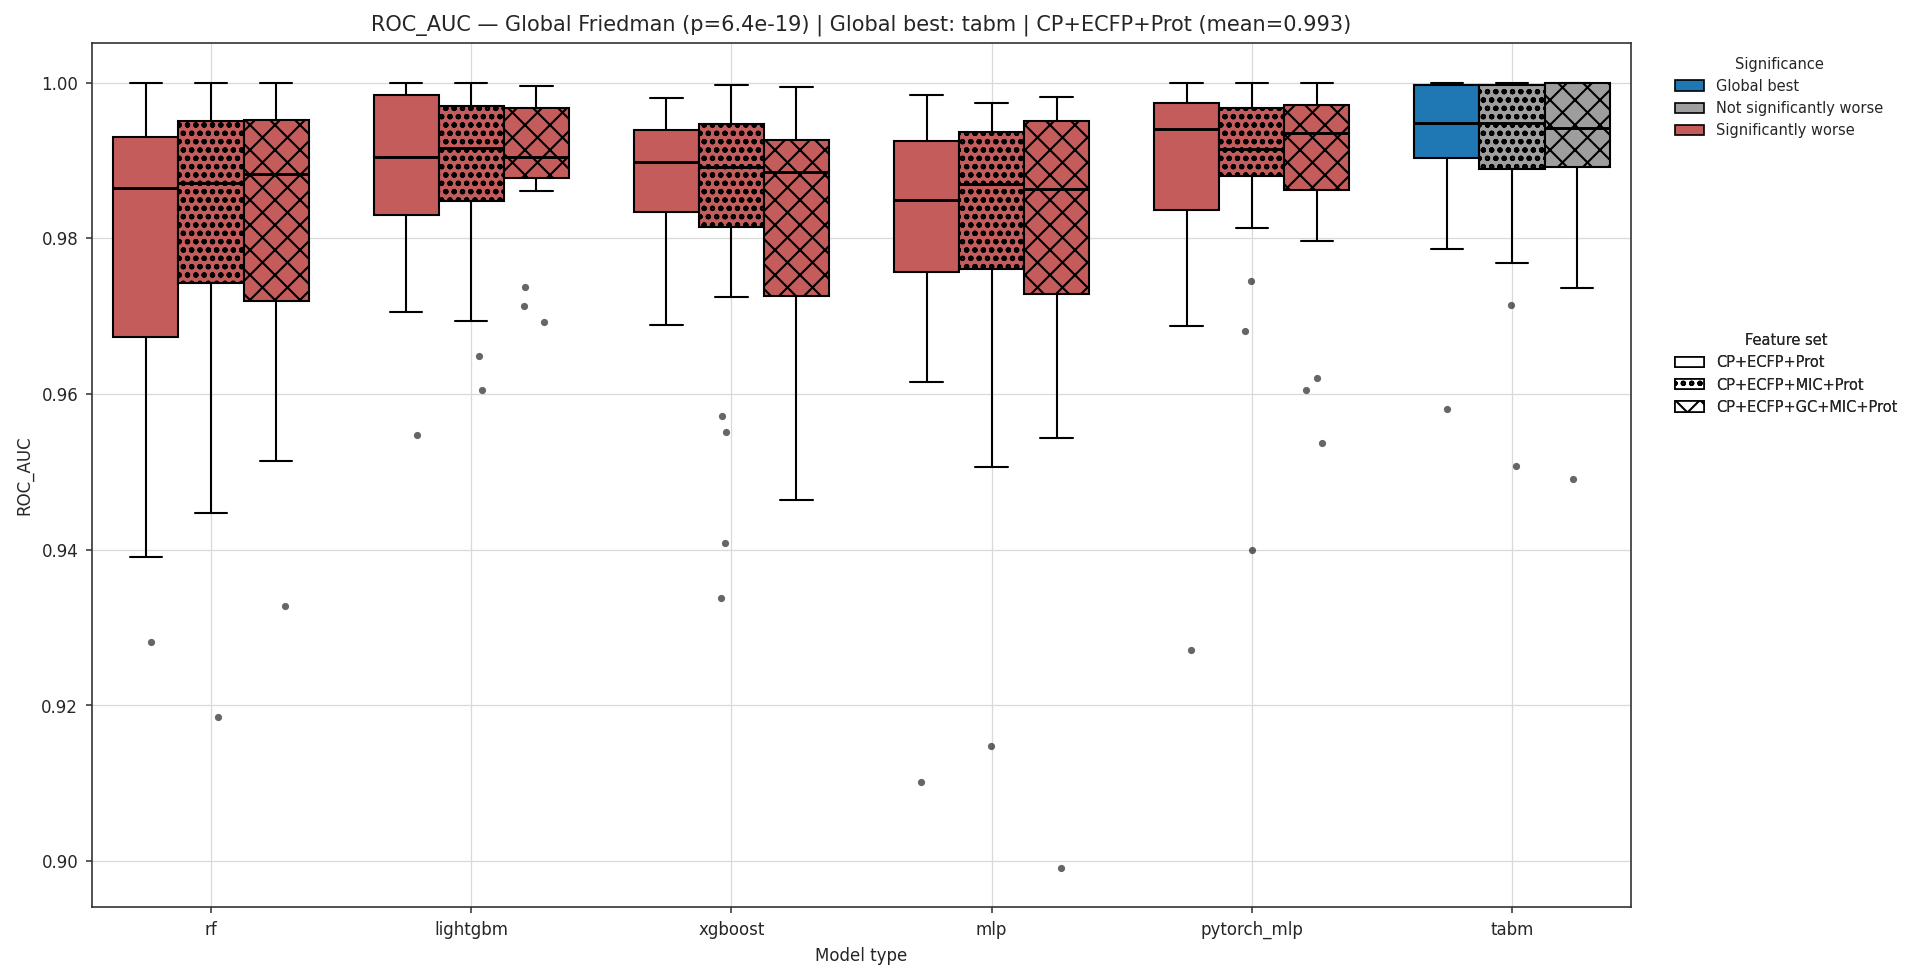

Saved: analysis_exports/Feature_augmentation_experiment/global_grouped_signif/global_grouped_roc_auc_HATCH.png


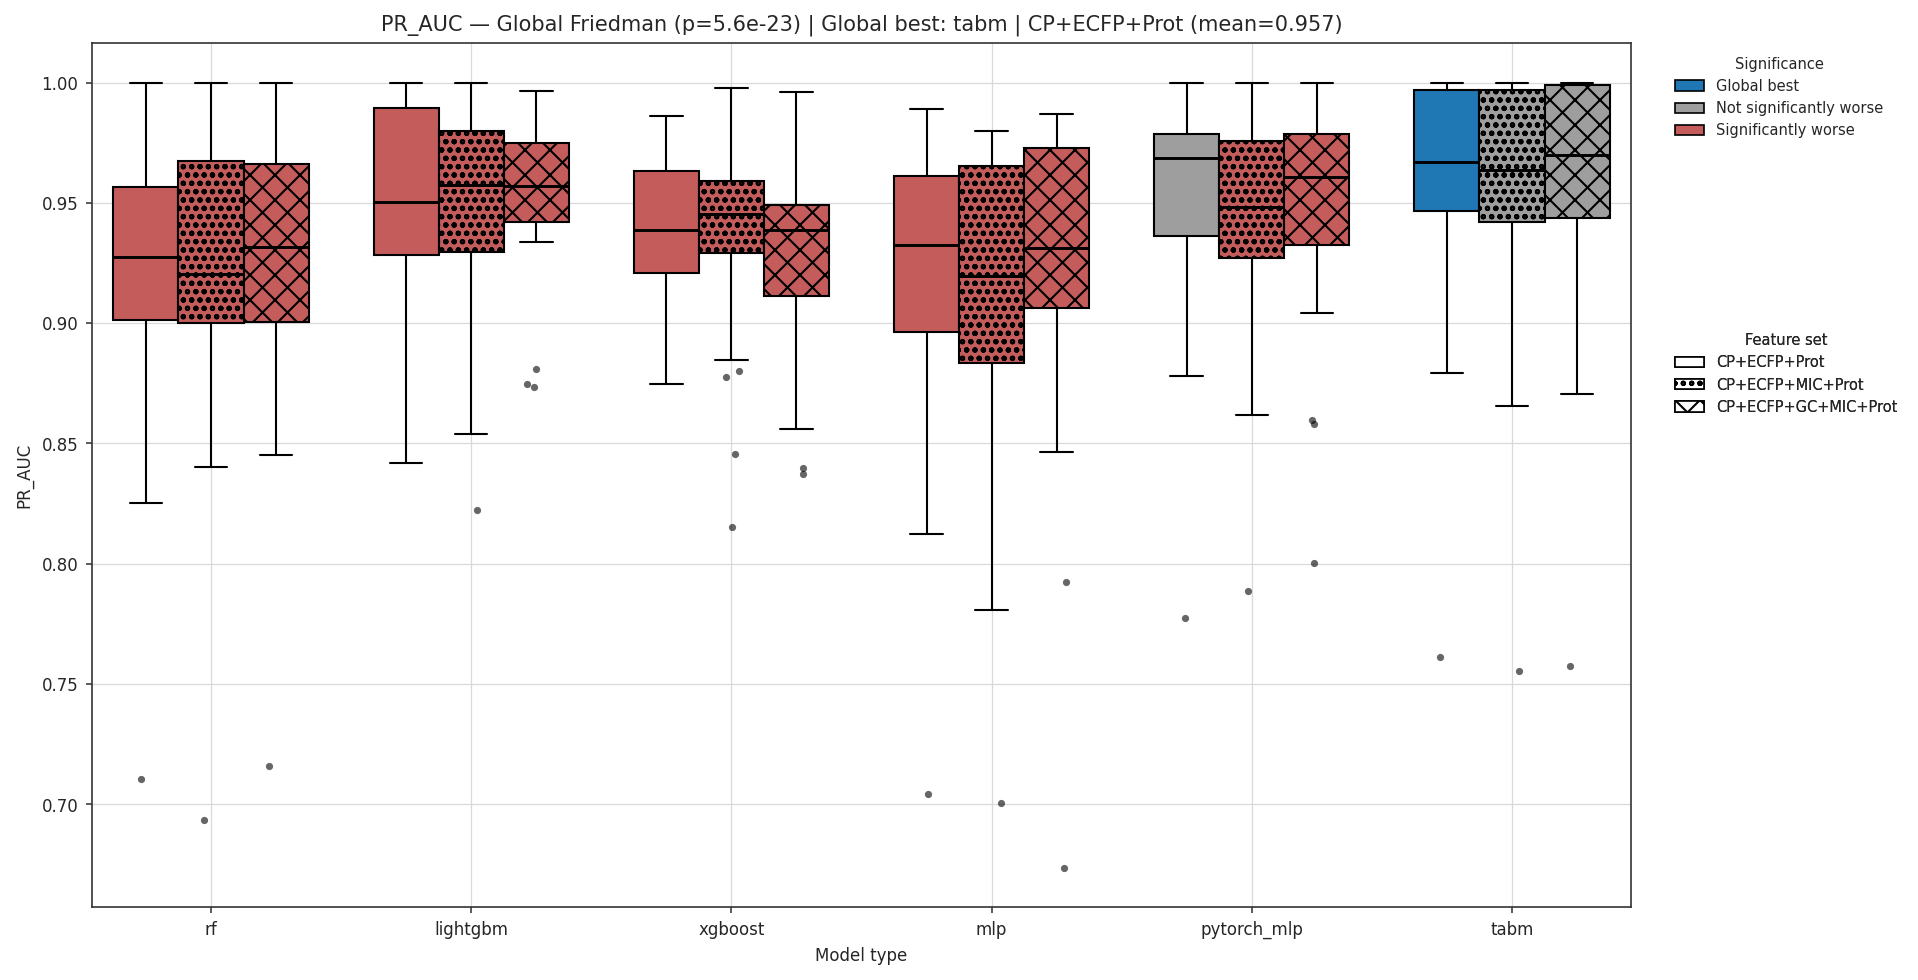

Saved: analysis_exports/Feature_augmentation_experiment/global_grouped_signif/global_grouped_pr_auc_HATCH.png


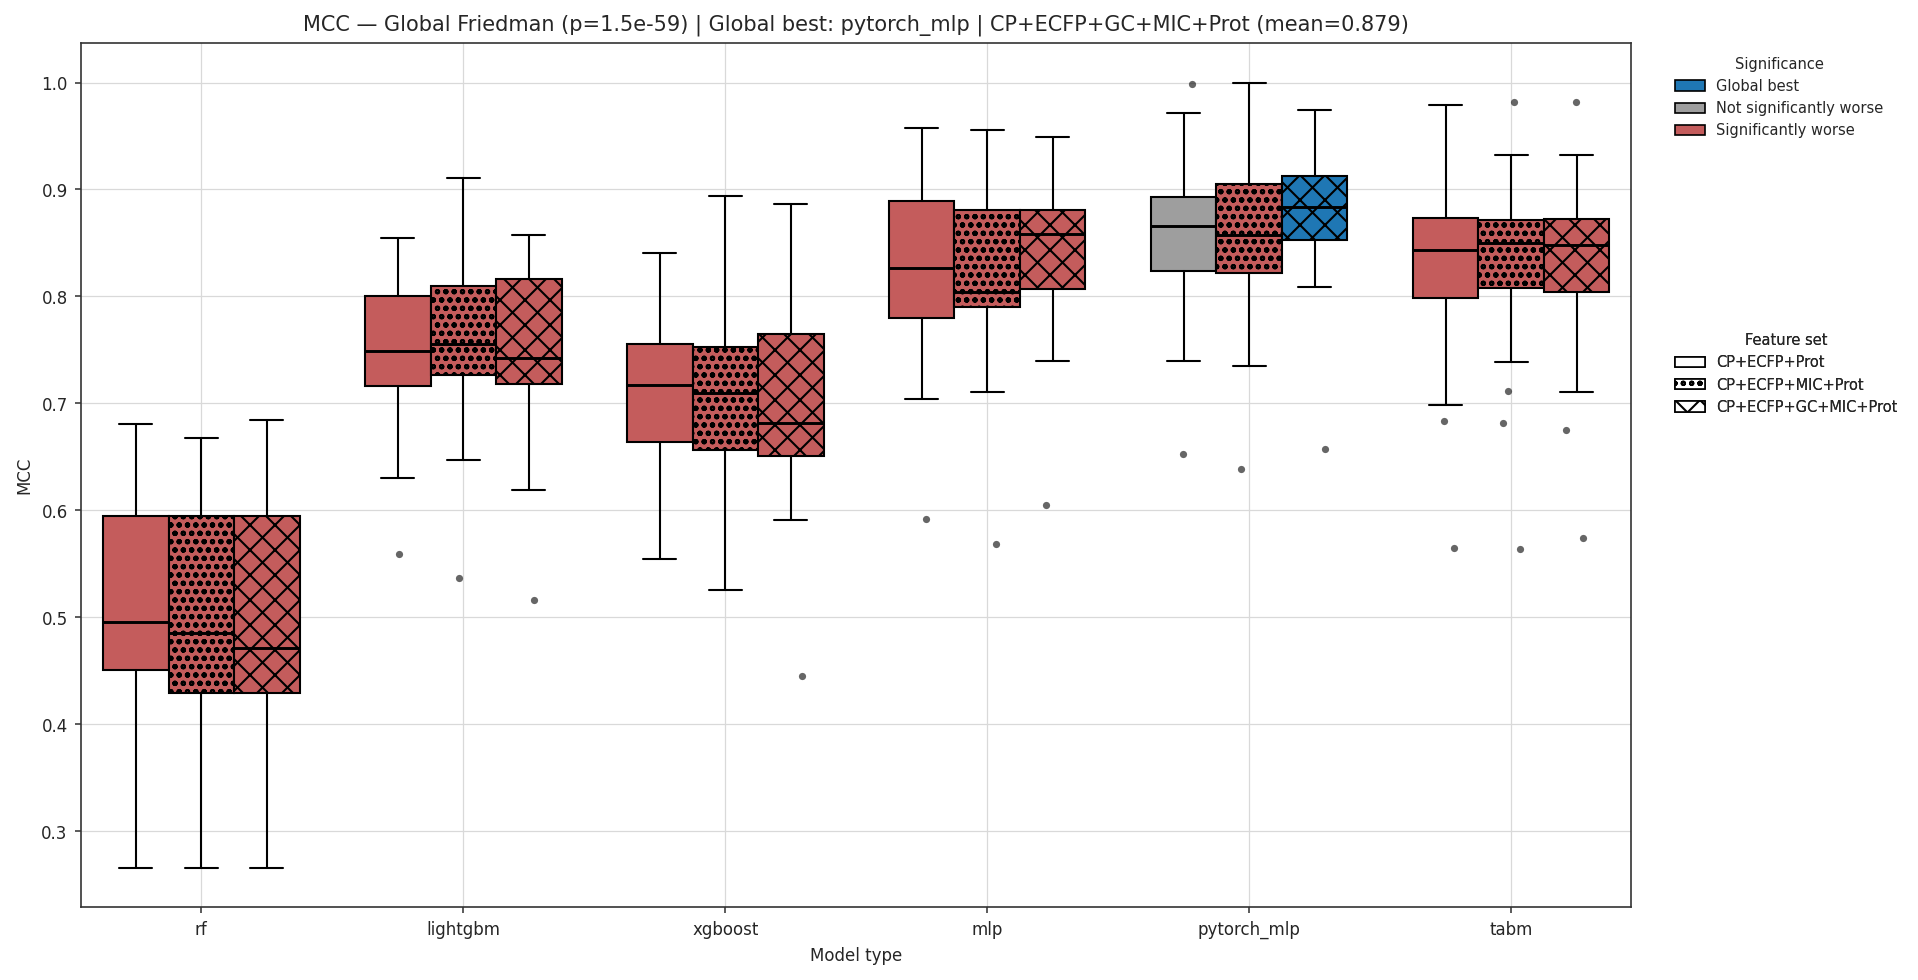

Saved: analysis_exports/Feature_augmentation_experiment/global_grouped_signif/global_grouped_mcc_HATCH.png


In [17]:
for met in METRICS:
    plot_grouped_with_significance_globalbest(met, show_points="outliers", whis=1.5)


In [18]:
from matplotlib import colors

def _fmt_q(v):
    if v is None or np.isnan(v): return ""
    return f"{v:.2f}" if v >= 1e-2 else f"{v:.1e}"

def plot_pairwise_q_heatmap_sig(
    pval_matrix: pd.DataFrame,
    means: pd.Series,
    alpha: float = 0.05,
    title: str | None = None,
    figsize=(10, 8),
    cmap_non_sig: str = "OrRd",
    sig_color: str = "#1f77b4",
    annotate: bool = True,
    annot_size: int = 7,
    cbar_decimals: int = 2,
    order: list[str] | None = None,   # <-- NEW: explicit order override
    savepath: Path | None = None,
):
    # Order: use override if given; else best → worst by mean
    if order is None:
        order = means.sort_values(ascending=False).index.tolist()
    q = pval_matrix.loc[order, order].copy()
    np.fill_diagonal(q.values, np.nan)

    # Lower triangle only
    mask_upper = np.triu(np.ones_like(q, dtype=bool), k=1)

    # Colormap: blue band for q<alpha, gradient for q≥alpha
    base = plt.get_cmap(cmap_non_sig, 256)
    n_total = 256
    n_blue  = max(1, int(np.floor(alpha * n_total)))
    n_grad  = n_total - n_blue
    grad = base(np.linspace(0, 1, max(n_grad, 1)))
    blue = np.tile(colors.to_rgba(sig_color), (n_blue, 1))
    merged = np.vstack([blue, grad])
    cmap = colors.ListedColormap(merged)
    norm = colors.Normalize(vmin=0.0, vmax=1.0)

    fig, ax = plt.subplots(figsize=figsize)
    hm = sns.heatmap(
        q, mask=mask_upper, cmap=cmap, norm=norm, vmin=0.0, vmax=1.0,
        cbar=True, linewidths=0.5, linecolor="white", square=True, ax=ax
    )

    cbar = hm.collections[0].colorbar
    ticks = np.array([0.0, alpha, 0.25, 0.5, 0.75, 1.0])
    ticks = np.unique(np.clip(ticks, 0, 1))
    cbar.set_ticks(ticks)
    cbar.set_ticklabels([f"{t:.{cbar_decimals}f}" for t in ticks])
    cbar.set_label("BH-adjusted p (q)")

    if annotate:
        for i in range(q.shape[0]):
            for j in range(q.shape[1]):
                if i <= j: 
                    continue
                val = q.iat[i, j]
                if np.isnan(val): 
                    continue
                ax.text(j + 0.5, i + 0.5, _fmt_q(val), ha="center", va="center",
                        fontsize=annot_size, color="black")

    ax.set_title(title or "Pairwise BH-adjusted p (q)")
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=60, ha="right")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    plt.tight_layout()
    if savepath:
        save_figure(plt.gcf(), savepath, dpi=200, bbox_inches="tight")
    plt.show()


In [19]:
def _global_condition_order_by_groups():
    def _lab(m, f): return f"{m} | {FEATURE_SHORT[f]}"
    present_models = [m for m in MODEL_ORDER if m in MODEL_ORDER]  # keep declared order
    return [_lab(m, f) for m in present_models for f in FEATURES]

def global_pairwise_q_heatmap_grouped(metric: str, alpha: float = ALPHA):
    long = _collect_balanced_long(metric)
    if long.empty: 
        print(f"[{metric}] No globally balanced data found.")
        return

    def _lab(m, f): return f"{m} | {FEATURE_SHORT[f]}"
    long = long.copy()
    long["cond"] = long.apply(lambda r: _lab(r["model_type"], r["feature_set"]), axis=1)
    wide = long.pivot_table(
        index="cv_cycle", columns="cond", values="value", aggfunc="mean"
    ).dropna(axis=0, how="any")
    _, means, Q = _posthoc_conover_friedman_vs_best(wide, alpha=alpha)

    # reorder by model-group, then feature
    order = [c for c in _global_condition_order_by_groups() if c in Q.columns]
    Qg = Q.loc[order, order]; mg = means.reindex(order)

    # --- build and save plot ---
    outpng = OUTDIR / f"global_pairwise_{metric}_qheatmap.svg"
 

    plot_pairwise_q_heatmap_sig(
        pval_matrix=Q,
        means=means,
        alpha=alpha,
        title=f"{metric.upper()} — pairwise BH q-values",
        figsize=(12, 10),
        annotate=True,
        order=order, 
        savepath=outpng,  # <-- enforce grouped order
    )
    print(f"Saved: {outpng}")

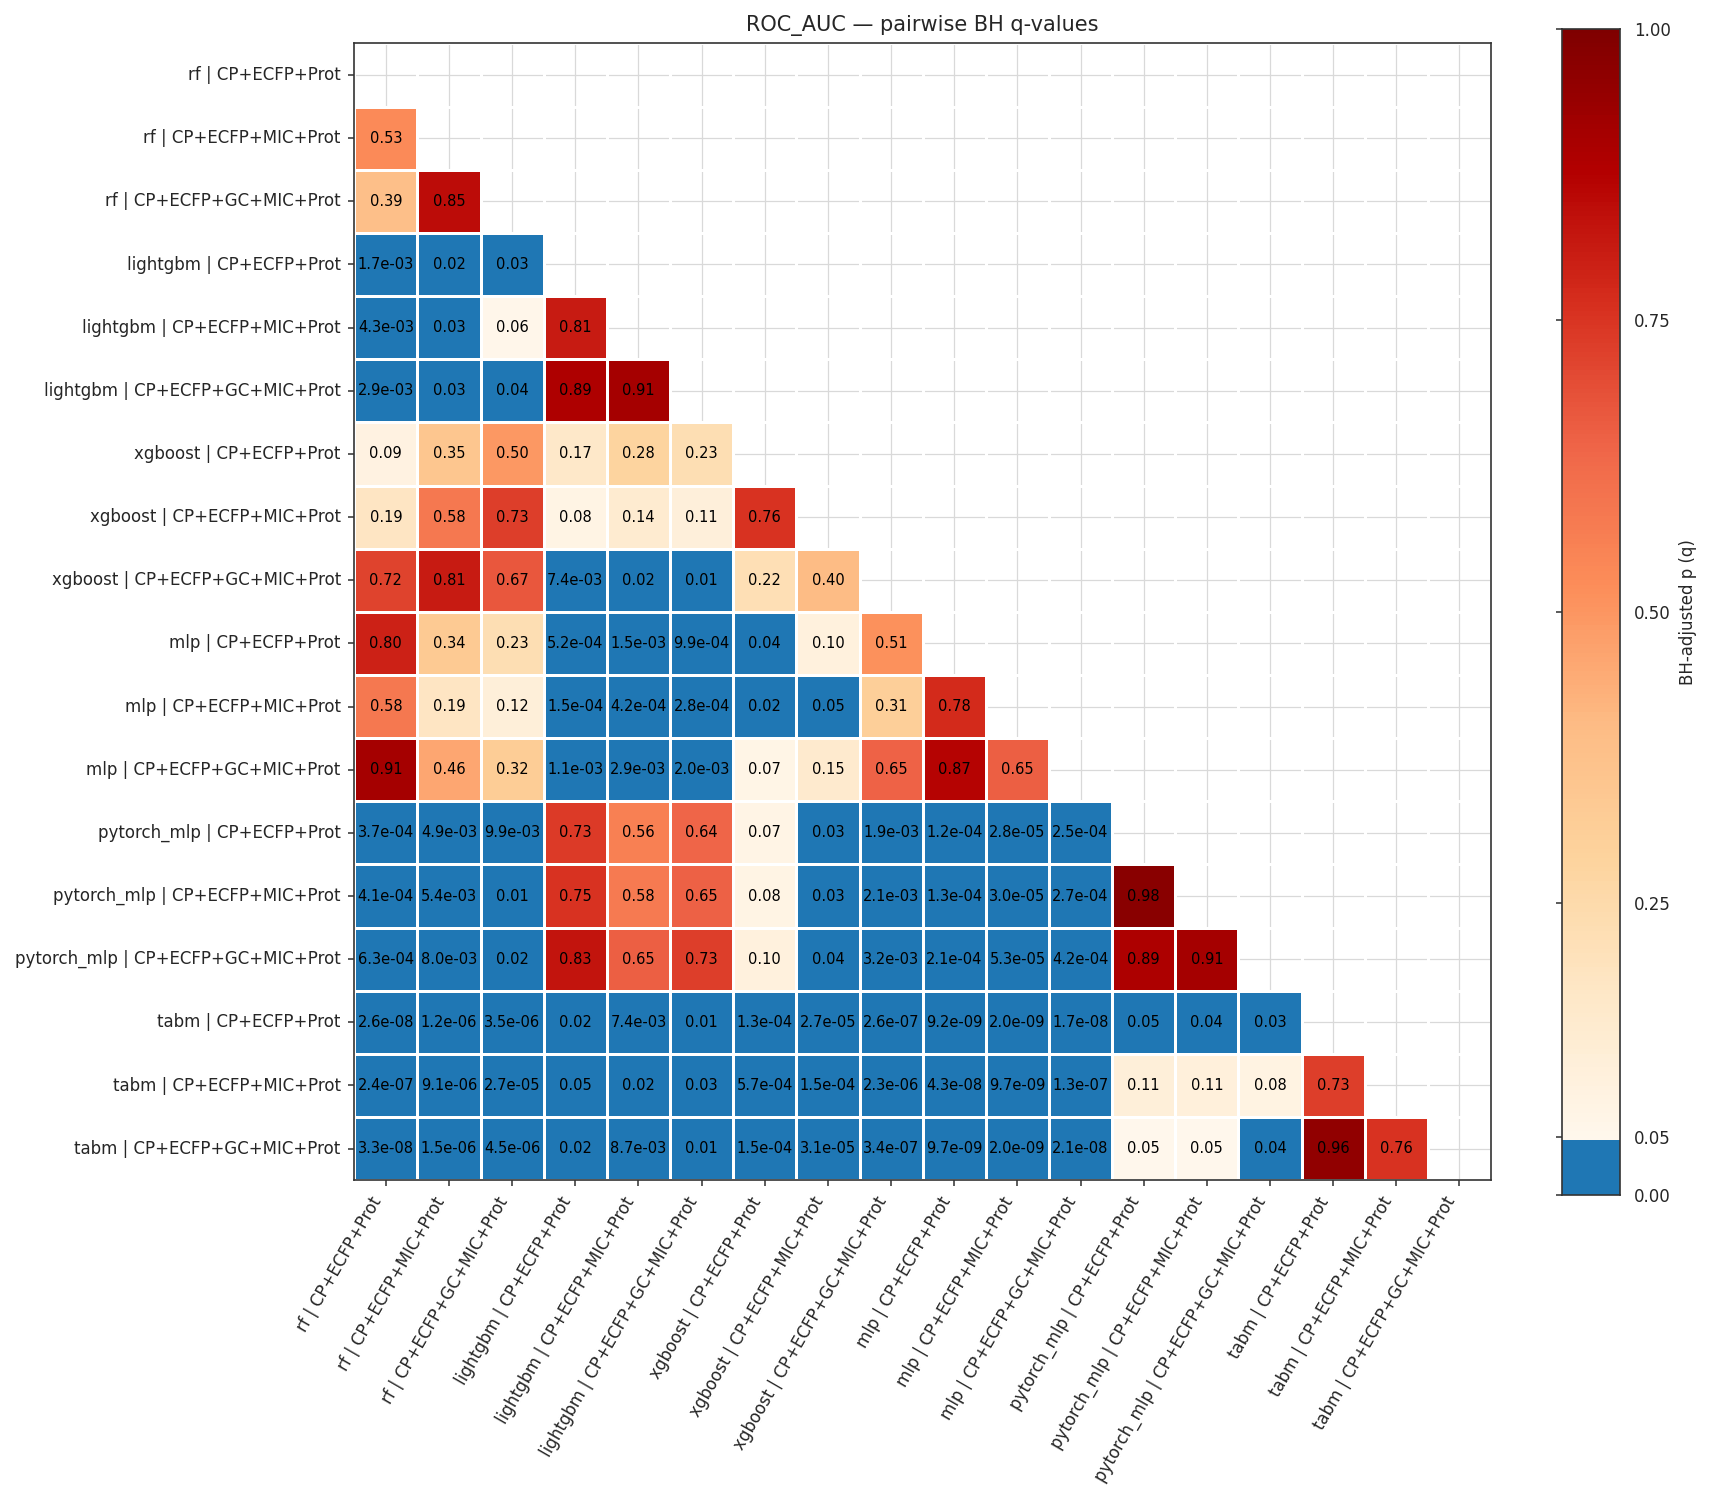

Saved: analysis_exports/Feature_augmentation_experiment/global_grouped_signif/global_pairwise_roc_auc_qheatmap.svg


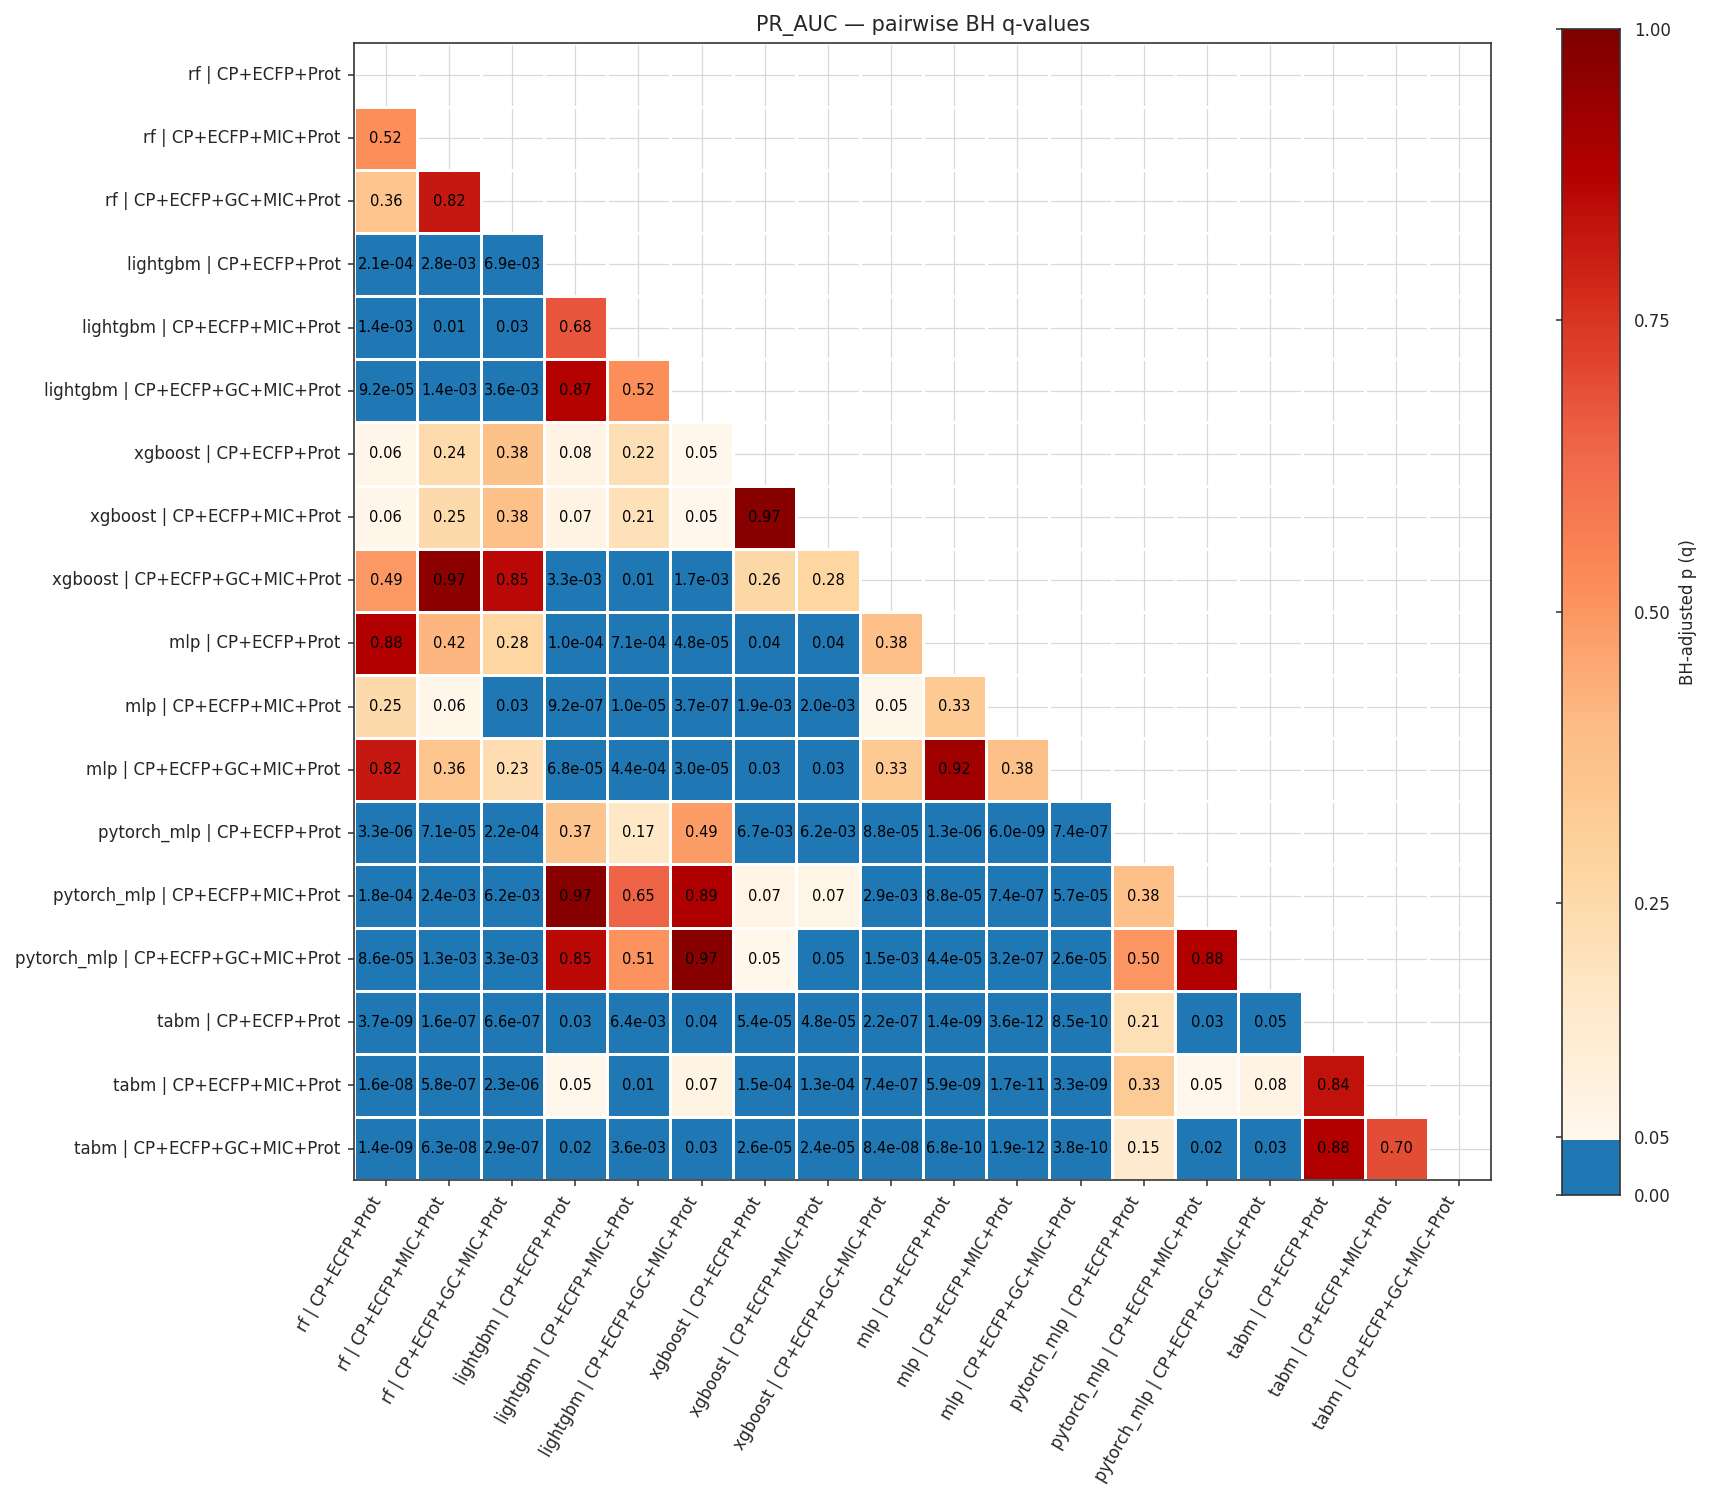

Saved: analysis_exports/Feature_augmentation_experiment/global_grouped_signif/global_pairwise_pr_auc_qheatmap.svg


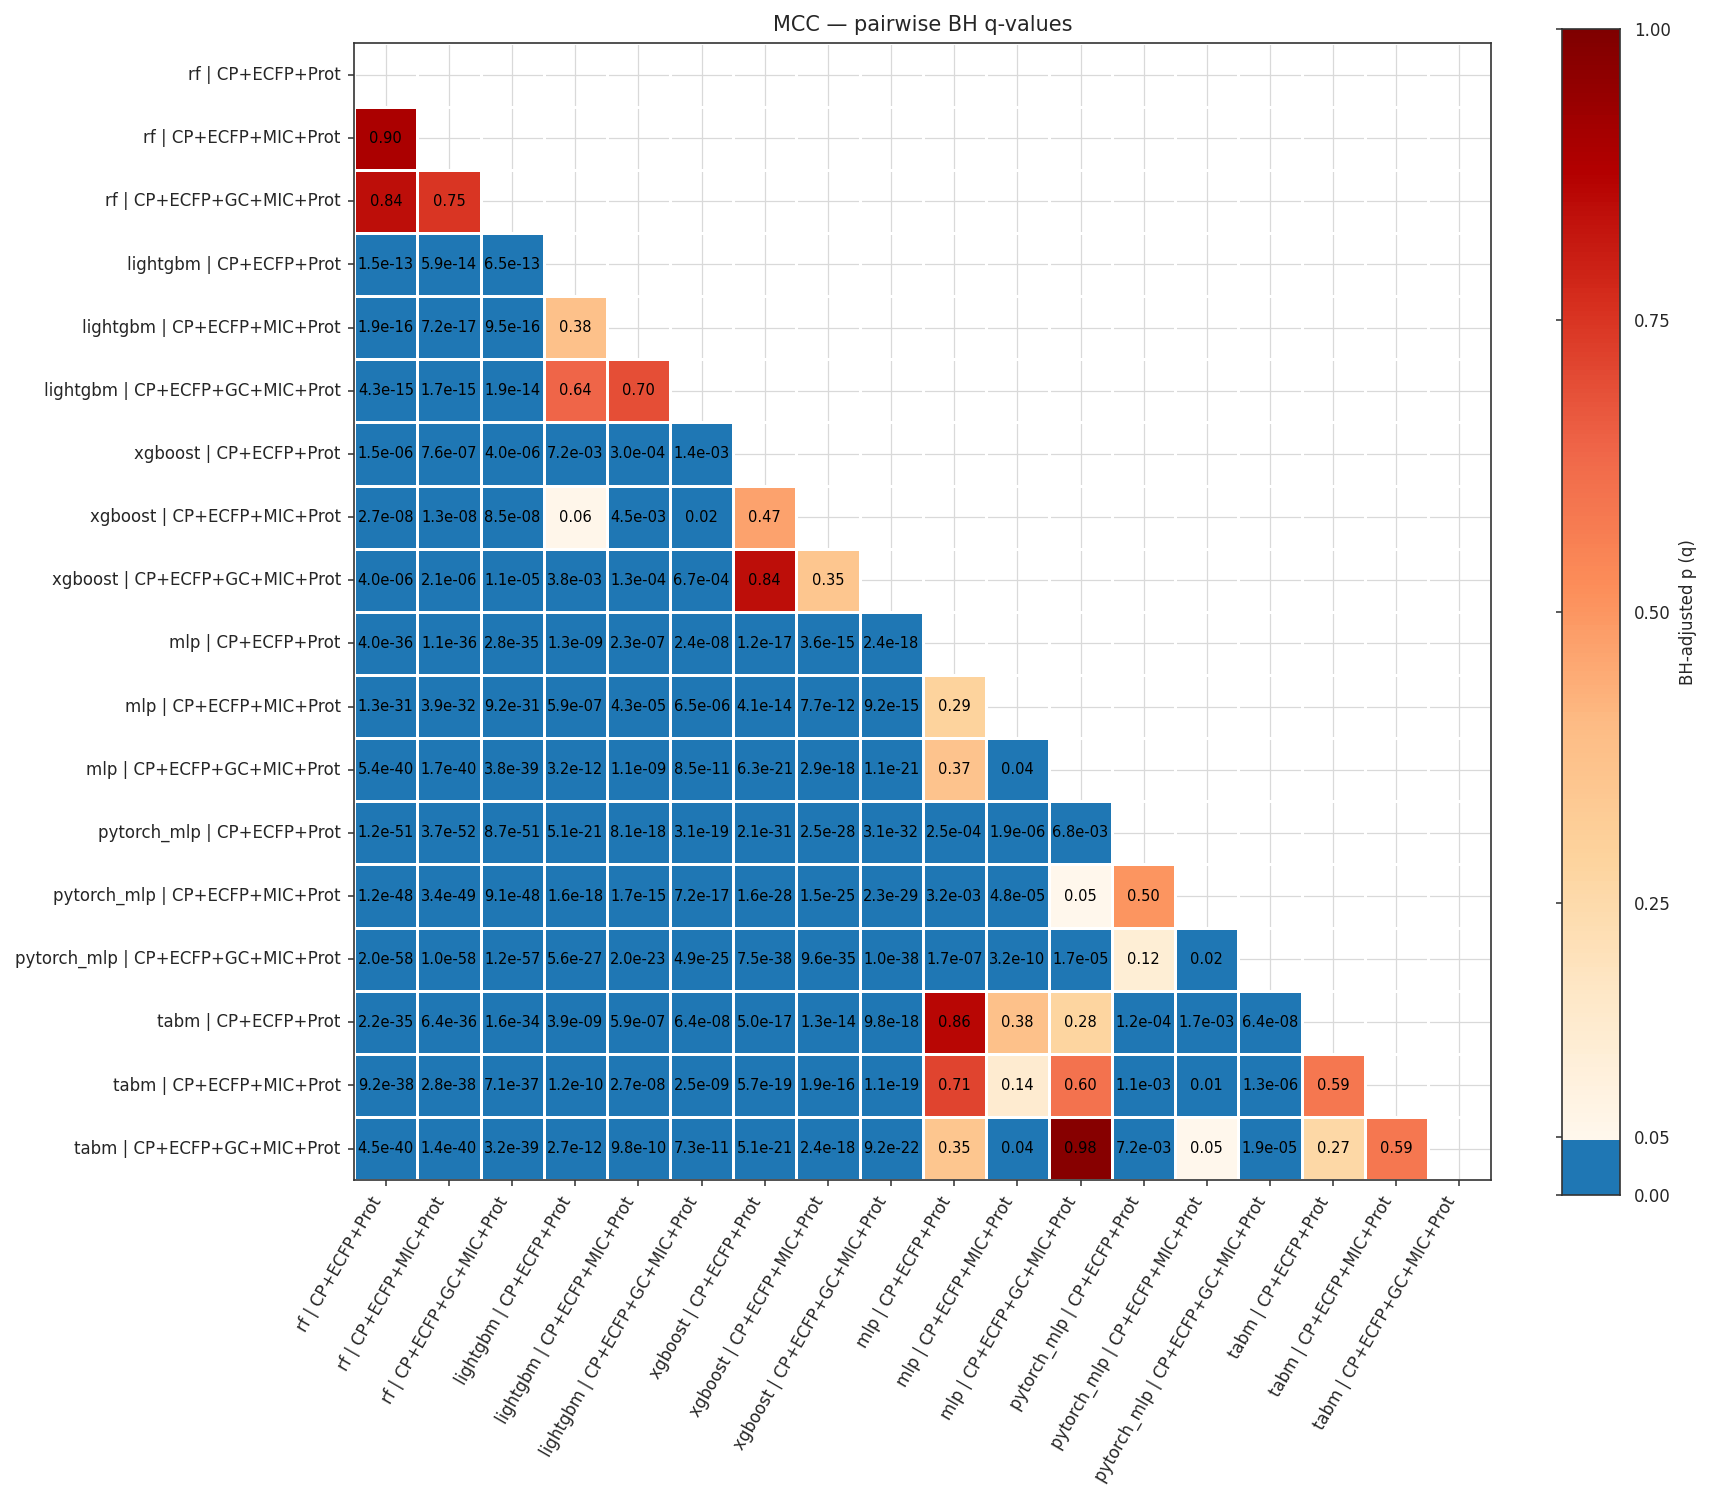

Saved: analysis_exports/Feature_augmentation_experiment/global_grouped_signif/global_pairwise_mcc_qheatmap.svg


In [20]:
for met in METRICS:   # e.g., ["roc_auc","pr_auc","mcc"]
    global_pairwise_q_heatmap_grouped(met, alpha=ALPHA)
